# Bài 7: Đánh giá mô hình
**Học máy ứng dụng — Trường Đại học Văn Lang, Khoa Công nghệ Thông tin**

Lời giải theo `Lab07_DanhGiaMoHinh.pdf` của ThS. Nguyễn Thái Anh. Phần A gồm **6 bước thực hành**;
phần B gồm **6 bài tập**, kèm giải thích, kiểm chứng và hình minh họa như Lab5.

**Dữ liệu:** `sinh_vien_bo_hoc.csv` (1.200 sinh viên), `gia_nha.csv` và bộ chữ số load_digits.

**Cách chạy:** giải nén gói dữ liệu của lab để có `data/` cạnh notebook, rồi chọn
**Restart Kernel and Run All Cells**. Có thể đặt CSV trực tiếp cạnh notebook. Mở Jupyter từ
gốc repo hoặc thư mục lab đều được. Kết quả được nhúng trong notebook, hình lưu thêm vào `images/`.

**Cài thư viện:** `pip install numpy pandas matplotlib scikit-learn jupyter`.
Các bộ dữ liệu đóng gói trong scikit-learn không cần tải mạng. CSV/PDF/ZIP không đưa lên GitHub.

## 0. Chuẩn bị môi trường

Với thí nghiệm phân loại, chia 75% học / 25% kiểm tra với `random_state=17`, `stratify=y`, giống đề.
Chuẩn hoá được đặt trong pipeline để chỉ học thống kê từ từng tập học của CV.
Chọn tham số hoặc ngưỡng bằng tập học; tập kiểm tra dùng báo cáo các thí nghiệm đã định trong đề.
Vì cùng tập kiểm tra được dùng nhiều lần trong bài thực hành, không xem các kết quả là đánh giá
độc lập cho một hệ thống đã được lựa chọn sau nhiều thí nghiệm.

Lần kiểm tra này giới hạn BLAS/OpenMP ở 1 luồng để giảm dao động và chi phí chạy trên dữ liệu nhỏ; môi trường nhiều luồng có thể cho chênh lệch thời gian và sai số tối ưu số học.

In [1]:
from pathlib import Path
from time import perf_counter
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

THU_MUC_LAB = Path('07. Accuracy_Metrics') if Path('07. Accuracy_Metrics').is_dir() else Path('.')
THU_MUC_ANH = THU_MUC_LAB / 'images'
THU_MUC_ANH.mkdir(exist_ok=True)


def doc_csv(ten, cot_bat_buoc):
    for p in (THU_MUC_LAB / 'data' / ten, THU_MUC_LAB / ten):
        if p.is_file():
            df = pd.read_csv(p)
            assert set(cot_bat_buoc).issubset(df.columns), f'Sai cột trong {ten}'
            assert len(df) > 0 and np.isfinite(df[cot_bat_buoc].to_numpy(dtype=float)).all(), ten
            print(f'{ten}: {df.shape[0]} dòng, {df.shape[1]} cột; không thiếu giá trị ở cột dùng')
            return df
    raise FileNotFoundError(f'Thiếu {ten}: hãy giải nén gói dữ liệu vào {THU_MUC_LAB}/data/.')


def chia(X, y):
    return train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)


def luu_hinh(ten):
    plt.savefig(THU_MUC_ANH / ten, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


def ve_bien(ax, mo_hinh, X, y, tieu_de):
    a = np.asarray(X)
    le = np.maximum(np.ptp(a, axis=0)*0.08, 0.1)
    xx, yy = np.meshgrid(np.linspace(a[:, 0].min()-le[0], a[:, 0].max()+le[0], 160),
                         np.linspace(a[:, 1].min()-le[1], a[:, 1].max()+le[1], 150))
    luoi = np.c_[xx.ravel(), yy.ravel()]
    if isinstance(X, pd.DataFrame):
        luoi = pd.DataFrame(luoi, columns=X.columns)
    zz = mo_hinh.predict(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#fed7d7', '#c3dafe'], alpha=0.8)
    ax.scatter(a[:, 0], a[:, 1], c=y, cmap='coolwarm_r', s=17, edgecolors='white', linewidths=0.3)
    ax.set_title(tieu_de)
    ax.set_xlabel(X.columns[0] if isinstance(X, pd.DataFrame) else 'x1')
    ax.set_ylabel(X.columns[1] if isinstance(X, pd.DataFrame) else 'x2')


plt.rcParams.update({'figure.figsize': (8, 5), 'figure.dpi': 110,
                     'font.family': 'DejaVu Sans', 'axes.grid': True, 'grid.alpha': 0.25})
print('Python', platform.python_version(), '| NumPy', np.__version__, '| pandas', pd.__version__)
print('scikit-learn', sklearn.__version__, '| matplotlib', plt.matplotlib.__version__)

Python 3.11.9 | NumPy 1.26.4 | pandas 2.3.3
scikit-learn 1.8.0 | matplotlib 3.10.8


---
# Phần A — Bài thực hành
## Bước 1 — Khi accuracy đánh lừa (Mục 2, `h1`)

Lớp dương 1 là **bỏ học**. Khoảng 10% sinh viên thuộc lớp này nên mô hình luôn đoán học tiếp
có thể đạt accuracy khoảng 90% nhưng không tìm được sinh viên bỏ học nào.

sinh_vien_bo_hoc.csv: 1200 dòng, 5 cột; không thiếu giá trị ở cột dùng


,diem_tb,so_buoi_vang,tin_chi_no,gio_lam_them,bo_hoc
0,8.0,3,0,0,0
1,8.9,5,1,7,0
2,3.3,3,1,4,0
3,6.4,3,0,7,0
4,7.9,3,5,23,0


Số mỗi lớp: {0: 1081, 1: 119}
Luôn đoán lớp đông: accuracy=0.9000; tìm ra 0/30 bạn bỏ học
Logistic: accuracy=0.9467; tìm ra 17/30 bạn bỏ học


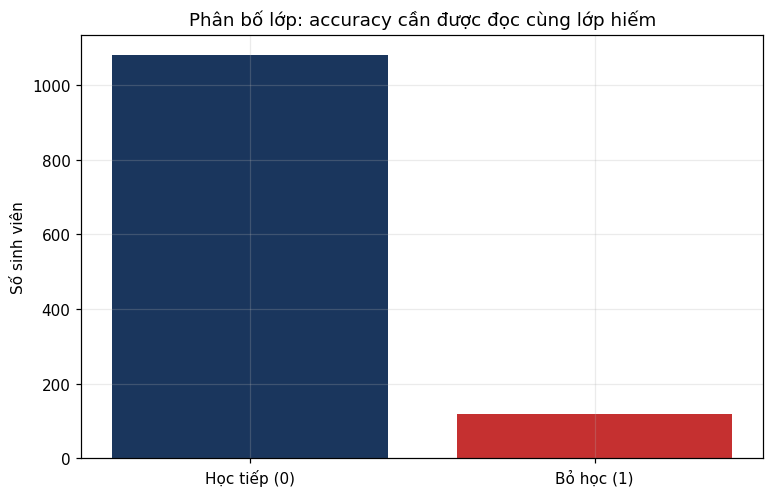

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (precision_score, recall_score, f1_score, classification_report,
    roc_auc_score, roc_curve, mean_absolute_error, mean_squared_error, r2_score)

sv = doc_csv('sinh_vien_bo_hoc.csv', ['diem_tb', 'so_buoi_vang', 'tin_chi_no', 'gio_lam_them', 'bo_hoc'])
display(sv.head()); print('Số mỗi lớp:', sv['bo_hoc'].value_counts().to_dict())
X, y = sv.drop(columns='bo_hoc'), sv['bo_hoc']
X_tr, X_te, y_tr, y_te = chia(X, y)
luoi = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
lr = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
du_luoi, du_lr = luoi.predict(X_te), lr.predict(X_te)
for ten, du in [('Luôn đoán lớp đông', du_luoi), ('Logistic', du_lr)]:
    print(f'{ten}: accuracy={accuracy_score(y_te, du):.4f}; tìm ra {sum((du==1)&(y_te==1))}/{y_te.sum()} bạn bỏ học')
plt.figure(); plt.bar(['Học tiếp (0)', 'Bỏ học (1)'], y.value_counts().reindex([0,1]), color=['#1a365d','#c53030'])
plt.ylabel('Số sinh viên'); plt.title('Phân bố lớp: accuracy cần được đọc cùng lớp hiếm')
luu_hinh('hinh1_lech_lop.png')

**Nhận xét từ lần chạy đã kiểm tra:** Có **119/1200** sinh viên bỏ học. Tập kiểm tra gồm 300 bạn, 30 bỏ học. Mô hình lười đạt **0.9000** nhưng tìm 0/30; logistic đạt **0.9467**, tìm 17/30. Accuracy cao vẫn có thể bỏ sót nhiều trường hợp cần hỗ trợ.

## Bước 2 — Ma trận nhầm lẫn (Mục 3, `h2`)

TP: báo nguy cơ và thật sự bỏ học; FP: báo nhầm; FN: bỏ sót; TN: xác định đúng học tiếp.
Với `labels=[0,1]`, ma trận là `[[TN,FP],[FN,TP]]`: hàng là thật, cột là đoán.

TP=17, FP=3, FN=13, TN=267; tổng=300
Accuracy từ bốn ô: 0.9466666666666667 ; số bạn được báo: 20


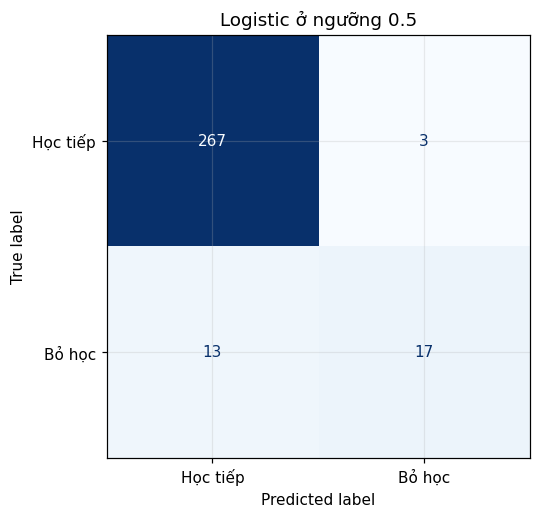

In [3]:
that = y_te.to_numpy()
tp = int(((that==1)&(du_lr==1)).sum()); fp = int(((that==0)&(du_lr==1)).sum())
fn = int(((that==1)&(du_lr==0)).sum()); tn = int(((that==0)&(du_lr==0)).sum())
print(f'TP={tp}, FP={fp}, FN={fn}, TN={tn}; tổng={tp+fp+fn+tn}')
cm = confusion_matrix(that, du_lr, labels=[0,1])
assert np.array_equal(cm, [[tn,fp],[fn,tp]])
assert tp+fp+fn+tn == len(that)
print('Accuracy từ bốn ô:', (tp+tn)/len(that), '; số bạn được báo:', tp+fp)
ConfusionMatrixDisplay(cm, display_labels=['Học tiếp', 'Bỏ học']).plot(cmap='Blues', colorbar=False)
plt.title('Logistic ở ngưỡng 0.5'); luu_hinh('hinh2_ma_tran_nham_lan.png')

**Nhận xét từ lần chạy đã kiểm tra:** **TN=267, FP=3, FN=13, TP=17**. Logistic báo 20 bạn có nguy cơ, trong đó 17 đúng; còn bỏ sót 13 bạn. Đọc ma trận theo đúng thứ tự nhãn để không đảo precision và recall.

## Bước 3 — Precision, recall và F1 (Mục 4, `h3`)

$P=TP/(TP+FP)$: bao nhiêu cảnh báo là đúng; $R=TP/(TP+FN)$: tìm được bao nhiêu người bỏ học;
$F1=2TP/(2TP+FP+FN)$. Bỏ sót và cảnh báo nhầm có tác động khác nhau nên cần báo cả P, R.

In [4]:
p_tay = tp/(tp+fp) if tp+fp else 0
r_tay = tp/(tp+fn) if tp+fn else 0
f_tay = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0
thu_vien = [precision_score(that,du_lr,zero_division=0), recall_score(that,du_lr,zero_division=0),
            f1_score(that,du_lr,zero_division=0)]
display(pd.DataFrame({'chi_so': ['precision','recall','F1'], 'tu_tinh': [p_tay,r_tay,f_tay], 'sklearn': thu_vien}))
assert np.allclose([p_tay,r_tay,f_tay], thu_vien)
print(classification_report(that, du_lr, target_names=['Học tiếp','Bỏ học'], digits=4, zero_division=0))

,chi_so,tu_tinh,sklearn
0,precision,0.850000,0.850000
1,recall,0.566667,0.566667
2,F1,0.680000,0.680000


              precision    recall  f1-score   support

    Học tiếp     0.9536    0.9889    0.9709       270
      Bỏ học     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



**Nhận xét từ lần chạy đã kiểm tra:** Precision **0.8500**, recall **0.5667**, F1 **0.6800** khớp phép tính tay. Tỷ lệ cảnh báo đúng cao nhưng mới tìm được hơn một nửa số bạn bỏ học.

## Bước 4 — Ngưỡng và cách chọn đúng (Mục 5, `h4`)

Hạ ngưỡng thường tăng recall đồng thời tăng cảnh báo nhầm. Bảng ngưỡng kiểm tra dưới đây là
minh họa các mốc đề cho sẵn; ngưỡng cuối được chọn từ xác suất **out-of-fold** trên tập học.
Mỗi sinh viên học nhận dự đoán từ mô hình chưa học sinh viên đó, gồm cả bộ chuẩn hoá.

,nguong,so_bao,TP,FP,FN,precision,recall,F1
0,0.5,20,17,3,13,0.8500,0.5667,0.6800
1,0.4,21,18,3,12,0.8571,0.6000,0.7059
2,0.3,29,21,8,9,0.7241,0.7000,0.7119
3,0.2,42,24,18,6,0.5714,0.8000,0.6667
4,0.1,61,26,35,4,0.4262,0.8667,0.5714


Ngưỡng theo F1 OOF: 0.25 ; F1 OOF: 0.6473429951690821


,nguong,so_bao,TP,FP,FN,precision,recall,F1
0,0.25,35,23,12,7,0.6571,0.7667,0.7077


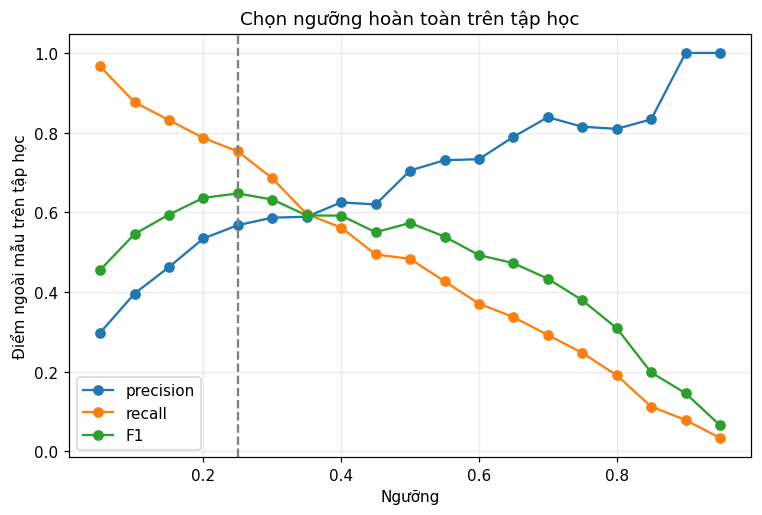

In [5]:
def diem_nguong(y_that, xs, nguong):
    du = np.asarray(xs)>=nguong; y0=np.asarray(y_that)
    return {'nguong': nguong, 'so_bao': int(du.sum()), 'TP': int(((y0==1)&du).sum()),
            'FP': int(((y0==0)&du).sum()), 'FN': int(((y0==1)&~du).sum()),
            'precision': precision_score(y0,du,zero_division=0),
            'recall': recall_score(y0,du,zero_division=0), 'F1': f1_score(y0,du,zero_division=0)}


xs_te = lr.predict_proba(X_te)[:,1]
display(pd.DataFrame([diem_nguong(y_te,xs_te,t) for t in [.5,.4,.3,.2,.1]]).round(4))
xs_oof = cross_val_predict(clone(lr), X_tr, y_tr, cv=5, method='predict_proba')[:,1]
cac_nguong = np.round(np.arange(.05,.96,.05),2)
bang_oof = pd.DataFrame([diem_nguong(y_tr,xs_oof,t) for t in cac_nguong])
t_tot = float(bang_oof.loc[bang_oof['F1'].idxmax(),'nguong'])
print('Ngưỡng theo F1 OOF:', t_tot, '; F1 OOF:', bang_oof['F1'].max())
display(pd.DataFrame([diem_nguong(y_te,xs_te,t_tot)]).round(4))
plt.figure()
for cot in ['precision','recall','F1']:
    plt.plot(bang_oof['nguong'],bang_oof[cot],'o-',label=cot)
plt.axvline(t_tot,color='gray',linestyle='--'); plt.xlabel('Ngưỡng'); plt.ylabel('Điểm ngoài mẫu trên tập học')
plt.title('Chọn ngưỡng hoàn toàn trên tập học'); plt.legend(); luu_hinh('hinh3_chon_nguong_oof.png')

**Nhận xét từ lần chạy đã kiểm tra:** Lưới OOF chọn ngưỡng **0.25**, F1 OOF **0.6473**. Áp vào kiểm tra cho precision **0.6571**, recall **0.7667**, F1 **0.7077**, báo 35 bạn. Hạ ngưỡng đổi precision lấy recall; không dùng bảng kiểm tra để chọn 0.25.

**Giải thích:** F1 OOF dùng để chọn trong lưới, không phải ước lượng độc lập sau lựa chọn.
Sau khi chọn, mô hình logistic đã học toàn bộ tập học cung cấp xác suất cho tập kiểm tra.
Ngưỡng tối ưu phụ thuộc mục tiêu; F1 cao nhất chưa chắc đáp ứng yêu cầu recall tối thiểu.

## Bước 5 — ROC, AUC và so các mô hình (Mục 6, `h5`)

ROC biểu diễn TPR=recall theo FPR=FP/(FP+TN). AUC đánh giá khả năng xếp hạng theo điểm liên tục,
không tính từ nhãn 0/1. AUC tốt không tự đảm bảo recall tốt ở ngưỡng 0.5, nhất là khi lớp lệch.

Một số điểm ROC:


,FPR,TPR
0,0.000000,0.000000
1,0.000000,0.033333
2,0.000000,0.400000
3,0.007407,0.400000
4,0.007407,0.533333
5,0.011111,0.533333


,mo_hinh,AUC,recall,F1
0,Logistic,0.9449,0.5667,0.6800
1,Naive Bayes,0.9336,0.3667,0.5116
2,KNN k=15,0.9274,0.2333,0.3684
3,Cây sâu 4,0.8803,0.4667,0.5957
4,Rừng 200 cây,0.9249,0.5667,0.6538
5,SVM RBF,0.8996,0.5000,0.6250


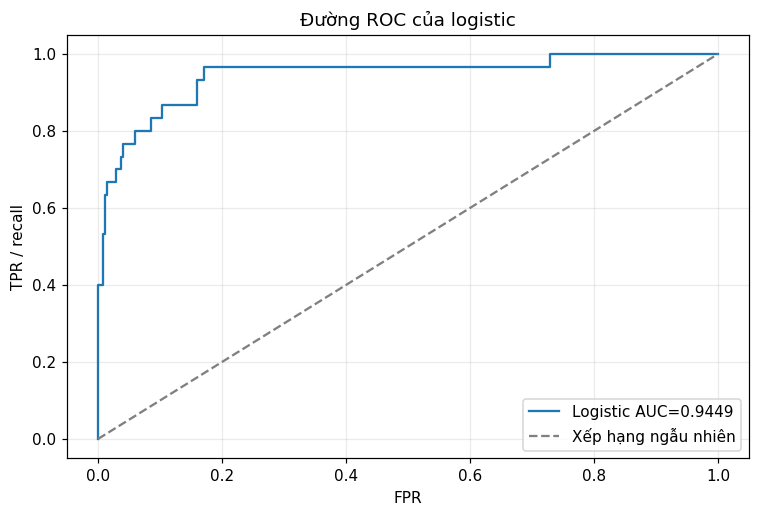

In [6]:
fpr_lr, tpr_lr, _ = roc_curve(y_te,xs_te)
print('Một số điểm ROC:'); display(pd.DataFrame({'FPR':fpr_lr,'TPR':tpr_lr}).head(6))
mo_hinh = {'Logistic':lr, 'Naive Bayes':GaussianNB(),
    'KNN k=15':make_pipeline(StandardScaler(),KNeighborsClassifier(15)),
    'Cây sâu 4':DecisionTreeClassifier(max_depth=4,random_state=0),
    'Rừng 200 cây':RandomForestClassifier(200,random_state=0),
    'SVM RBF':make_pipeline(StandardScaler(),SVC(probability=True,random_state=0))}
bang_mh, xs_mh = [], {}
for ten,mh in mo_hinh.items():
    mh.fit(X_tr,y_tr); xs=mh.predict_proba(X_te)[:,1]; xs_mh[ten]=xs
    bang_mh.append({'mo_hinh':ten,'AUC':roc_auc_score(y_te,xs),
                    'recall':recall_score(y_te,xs>=.5,zero_division=0),'F1':f1_score(y_te,xs>=.5,zero_division=0)})
display(pd.DataFrame(bang_mh).round(4))
plt.figure()
plt.plot(fpr_lr,tpr_lr,label=f'Logistic AUC={roc_auc_score(y_te,xs_te):.4f}')
plt.plot([0,1],[0,1],'--',color='gray',label='Xếp hạng ngẫu nhiên')
plt.xlabel('FPR'); plt.ylabel('TPR / recall'); plt.legend(); plt.title('Đường ROC của logistic')
luu_hinh('hinh4_roc_logistic.png')

**Nhận xét từ lần chạy đã kiểm tra:** AUC logistic **0.9449**, cao hơn rừng **0.9249** ở lần chia này. KNN có AUC 0.9274 nhưng recall ngưỡng 0.5 chỉ 0.2333: khả năng xếp hạng và điểm tại một ngưỡng là hai mặt khác nhau.

## Bước 6 — CV nhiều thước đo, phân tầng và cân bằng lớp (Mục 7, `h6`)

`class_weight='balanced'` tăng trọng số lỗi ở lớp ít mẫu khi học; không sinh thêm dữ liệu,
không bảo đảm mọi thước đo đều tăng. Phân tầng giữ tỷ lệ lớp gần nhau, không tăng số mẫu lớp hiếm.

In [7]:
khong_pt, co_pt = [], []
for rs in range(10):
    khong_pt.append(int(train_test_split(X,y,test_size=.25,random_state=rs)[3].sum()))
    co_pt.append(int(train_test_split(X,y,test_size=.25,random_state=rs,stratify=y)[3].sum()))
print('Số bỏ học kiểm tra, không phân tầng:',khong_pt)
print('Số bỏ học kiểm tra, có phân tầng:',co_pt)
display(pd.DataFrame([{'thuoc_do':s,'CV_mean':cross_val_score(clone(lr),X_tr,y_tr,cv=5,scoring=s).mean()}
                      for s in ['accuracy','precision','recall','f1']]).round(4))
cb_lr=make_pipeline(StandardScaler(),LogisticRegression(class_weight='balanced')).fit(X_tr,y_tr)
display(pd.DataFrame([dict(cach=ten,**diem_nguong(y_te,m.predict_proba(X_te)[:,1],.5))
                      for ten,m in [('Bình thường',lr),('Cân bằng lớp',cb_lr)]]).round(4))

Số bỏ học kiểm tra, không phân tầng: [22, 26, 35, 29, 32, 27, 28, 20, 27, 23]
Số bỏ học kiểm tra, có phân tầng: [30, 30, 30, 30, 30, 30, 30, 30, 30, 30]


,thuoc_do,CV_mean
0,accuracy,0.9289
1,precision,0.7044
2,recall,0.4810
3,f1,0.5652


,cach,nguong,so_bao,TP,FP,FN,precision,recall,F1
0,Bình thường,0.5,20,17,3,13,0.8500,0.5667,0.6800
1,Cân bằng lớp,0.5,58,26,32,4,0.4483,0.8667,0.5909


**Nhận xét từ lần chạy đã kiểm tra:** Không phân tầng cho số bỏ học trong tập kiểm tra dao động **20–35**, phân tầng giữ **30** ở cả 10 lần. Logistic balanced tăng recall **0.5667→0.8667**, giảm precision **0.8500→0.4483**; số cảnh báo tăng 20→58.

---
# Phần B — Bài tập
## Bài tập 1 — Tự viết hàm đánh giá chỉ bằng NumPy

Khi không dự đoán dương, precision không xác định về mặt toán học. Quy ước trả 0 để so đúng
`zero_division=0` của sklearn; ghi rõ quy ước thay vì cho rằng mô hình đạt precision hoàn hảo.

In [8]:
def danh_gia(y_that,y_doan):
    a,b=np.asarray(y_that),np.asarray(y_doan)
    if a.ndim!=1 or b.shape!=a.shape or a.size==0:
        raise ValueError('Cần hai mảng 1D cùng chiều dài, không rỗng.')
    if not np.isin(a,[0,1]).all() or not np.isin(b,[0,1]).all():
        raise ValueError('Hàm dành cho nhãn 0/1.')
    tp=int(((a==1)&(b==1)).sum()); fp=int(((a==0)&(b==1)).sum()); fn=int(((a==1)&(b==0)).sum())
    return {'accuracy':float((a==b).mean()), 'precision':tp/(tp+fp) if tp+fp else 0.,
            'recall':tp/(tp+fn) if tp+fn else 0., 'F1':2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.}


for ten,du in [('Logistic',du_lr),('Mô hình lười',du_luoi)]:
    tu_tinh=danh_gia(y_te,du)
    sk=dict(accuracy=accuracy_score(y_te,du),precision=precision_score(y_te,du,zero_division=0),
            recall=recall_score(y_te,du,zero_division=0),F1=f1_score(y_te,du,zero_division=0))
    print(ten); display(pd.DataFrame({'numpy':tu_tinh,'sklearn':sk}).round(6))
    assert np.allclose(list(tu_tinh.values()),list(sk.values()))
assert danh_gia([0,0],[0,0])['precision']==0
assert danh_gia([1,1],[0,0])['recall']==0

Logistic


,numpy,sklearn
accuracy,0.946667,0.946667
precision,0.850000,0.850000
recall,0.566667,0.566667
F1,0.680000,0.680000


Mô hình lười


,numpy,sklearn
accuracy,0.9,0.9
precision,0.0,0.0
recall,0.0,0.0
F1,0.0,0.0


**Nhận xét từ lần chạy đã kiểm tra:** Hàm NumPy khớp bốn chỉ số sklearn cho cả logistic và mô hình lười. Với mô hình lười không có dự đoán dương, precision là 0/0; hàm trả **0 theo quy ước**, không phải một precision được xác định theo tỷ lệ thông thường.

## Bài tập 2 — Báo cáo cho 10 chữ số

Dùng lại cấu hình SVC RBF và cách chia Lab6. Macro lấy trung bình đều giữa các lớp;
weighted lấy trung bình theo số mẫu thật (support). Bộ chữ số có số ảnh mỗi lớp gần nhau nên
hai trung bình thường gần nhau; micro và accuracy trùng trong phân loại đa lớp một nhãn.

In [9]:
Xd,yd=load_digits(return_X_y=True)
Xd_tr,Xd_te,yd_tr,yd_te=chia(Xd,yd)
svm_digits=SVC().fit(Xd_tr,yd_tr); du_digits=svm_digits.predict(Xd_te)
report=classification_report(yd_te,du_digits,output_dict=True,zero_division=0)
print(classification_report(yd_te,du_digits,digits=4,zero_division=0))
bang_report=pd.DataFrame(report).T
for chi_so in ['precision','recall']:
    lop=bang_report.loc[[str(i) for i in range(10)],chi_so]
    print(f'Lớp có {chi_so} thấp nhất:',lop[lop==lop.min()].index.tolist(),'; điểm:',lop.min())

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Lớp có precision thấp nhất: ['8'] ; điểm: 0.9767441860465116
Lớp có recall thấp nhất: ['8'] ; điểm: 0.9767441860465116


**Nhận xét từ lần chạy đã kiểm tra:** Chữ số **8** có cả recall và precision thấp nhất, cùng **0.9767**; 43 ảnh lớp 8 trong kiểm tra so với 44–46 ở đa số lớp còn lại. Support gần đều làm macro và weighted gần nhau.

## Bài tập 3 — Ngưỡng lớn nhất đạt recall OOF ≥ 0.8

Xét **mọi xác suất OOF phân biệt** thay vì một lưới thưa. Với quy tắc `>=`, recall chỉ đổi khi
đi qua các mức này. Chọn mức lớn nhất thỏa yêu cầu trên tập học; không dò lại từ nhãn kiểm tra.
Recall trên kiểm tra vẫn có thể dưới 0.8 do dao động mẫu và khác biệt phân phối.

In [10]:
# Vector hóa phép đếm tại mọi ngưỡng, gồm cả trường hợp các xác suất trùng nhau.
nguong_chinh_xac=np.unique(np.r_[0.,xs_oof,1.])
recall_oof=((xs_oof[np.asarray(y_tr)==1,None]>=nguong_chinh_xac).mean(axis=0))
t_80=float(nguong_chinh_xac[recall_oof>=.8].max())
print('Ngưỡng lớn nhất đạt recall yêu cầu:',t_80)
print('Kết quả OOF:'); display(pd.DataFrame([diem_nguong(y_tr,xs_oof,t_80)]).round(4))
kq_80=diem_nguong(y_te,xs_te,t_80)
print('Áp cho kiểm tra một lần:'); display(pd.DataFrame([kq_80]).round(4))
print('Kiểm tra đạt recall ≥0.8:',kq_80['recall']>=.8)
assert recall_score(y_tr,xs_oof>=t_80)>=.8
assert not np.any(recall_oof[nguong_chinh_xac>t_80]>=.8)

Ngưỡng lớn nhất đạt recall yêu cầu: 0.17177364490833014
Kết quả OOF:


,nguong,so_bao,TP,FP,FN,precision,recall,F1
0,0.1718,141,72,69,17,0.5106,0.809,0.6261


Áp cho kiểm tra một lần:


,nguong,so_bao,TP,FP,FN,precision,recall,F1
0,0.1718,47,24,23,6,0.5106,0.8,0.6234


Kiểm tra đạt recall ≥0.8: True


**Nhận xét từ lần chạy đã kiểm tra:** Ngưỡng lớn nhất đạt yêu cầu OOF là **0.1717736449**, recall OOF **72/89≈0.8090**. Trên kiểm tra đạt đúng **24/30=0.8000**, precision **24/47≈0.5106**, báo **47 bạn** (23 cảnh báo nhầm). Đạt yêu cầu ở lần chia này không bảo đảm mọi tập dữ liệu mới đều đạt.

## Bài tập 4 — Tự vẽ hai đường ROC, lưu `roc.png`

So logistic và rừng đã học trên cùng tập dữ liệu. AUC so tổng thể; một đường có AUC lớn hơn
vẫn có thể thấp hơn đường kia ở một vùng FPR. Cần kiểm tra cả vùng đường cắt nhau.

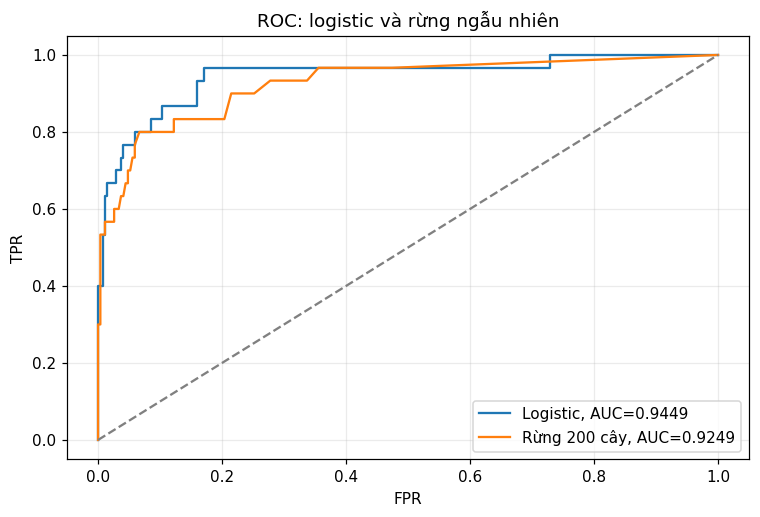

Có vùng logistic cao hơn rừng: True
Có vùng rừng cao hơn logistic: True
Hai đường có đổi thứ tự cao/thấp: True


In [11]:
plt.figure()
fpr_rf,tpr_rf,_=roc_curve(y_te,xs_mh['Rừng 200 cây'])
for ten,fpr,tpr in [('Logistic',fpr_lr,tpr_lr),('Rừng 200 cây',fpr_rf,tpr_rf)]:
    plt.plot(fpr,tpr,label=f'{ten}, AUC={roc_auc_score(y_te,xs_mh[ten]):.4f}')
plt.plot([0,1],[0,1],'--',color='gray'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend()
plt.title('ROC: logistic và rừng ngẫu nhiên'); luu_hinh('roc.png')
# Giữ nguyên các điểm lặp FPR của đoạn ROC thẳng đứng khi nội suy.
# Thử hợp mốc và trung điểm mỗi khoảng để quan sát đổi thứ tự hai đường.
hop=np.unique(np.r_[fpr_lr,fpr_rf])
moc=np.unique(np.r_[hop,(hop[:-1]+hop[1:])/2])
hieu=np.interp(moc,fpr_lr,tpr_lr)-np.interp(moc,fpr_rf,tpr_rf)
print('Có vùng logistic cao hơn rừng:',bool((hieu>1e-10).any()))
print('Có vùng rừng cao hơn logistic:',bool((hieu< -1e-10).any()))
print('Hai đường có đổi thứ tự cao/thấp:',bool((hieu>1e-10).any() and (hieu< -1e-10).any()))

**Nhận xét từ lần chạy đã kiểm tra:** Logistic có AUC cao hơn nhưng có cả vùng rừng cao hơn logistic và vùng logistic cao hơn rừng: **hai đường đổi thứ tự/cắt nhau**. Không có mô hình nào luôn trội ở mọi mức FPR.

## Bài tập 5 — Cân bằng lớp cho SVM và rừng

Dùng nhãn từ `.predict` để so tác dụng class_weight tại quy tắc quyết định mặc định. Với SVC,
nhãn này theo dấu decision_function; không đồng nhất nó với ngưỡng 0.5 của xác suất đã hiệu chỉnh.

In [12]:
bang_cb=[]
for ten,tao in [('RandomForest',lambda w:RandomForestClassifier(200,random_state=0,class_weight=w)),
                ('SVC',lambda w:make_pipeline(StandardScaler(),SVC(class_weight=w)))]:
    for w in [None,'balanced']:
        mh=tao(w).fit(X_tr,y_tr); du=mh.predict(X_te)
        bang_cb.append(dict(mo_hinh=ten,can_bang=str(w),**danh_gia(y_te,du)))
bang_cb=pd.DataFrame(bang_cb); display(bang_cb.round(4))
for chi_so in ['precision','recall','F1']:
    doi=bang_cb.pivot(index='mo_hinh',columns='can_bang',values=chi_so)
    delta=doi['balanced']-doi['None']
    print(f'Đổi {chi_so}:',delta.round(4).to_dict(),'; lớn nhất theo trị tuyệt đối:',delta.abs().idxmax())

,mo_hinh,can_bang,accuracy,precision,recall,F1
0,RandomForest,None,0.9400,0.7727,0.5667,0.6538
1,RandomForest,balanced,0.9267,0.7500,0.4000,0.5217
2,SVC,None,0.9433,0.8824,0.5000,0.6383
3,SVC,balanced,0.8800,0.4464,0.8333,0.5814


Đổi precision: {'RandomForest': -0.0227, 'SVC': -0.4359} ; lớn nhất theo trị tuyệt đối: SVC
Đổi recall: {'RandomForest': -0.1667, 'SVC': 0.3333} ; lớn nhất theo trị tuyệt đối: SVC
Đổi F1: {'RandomForest': -0.1321, 'SVC': -0.0569} ; lớn nhất theo trị tuyệt đối: RandomForest


**Nhận xét từ lần chạy đã kiểm tra:** SVC thay đổi mạnh hơn về precision và recall: recall **0.5000→0.8333**, precision **0.8824→0.4464**. Với rừng, recall lại giảm **0.5667→0.4000**. Nếu xét độ giảm F1, rừng thay đổi nhiều hơn; câu “thay đổi nhiều nhất” phải nêu rõ thước đo.

## Bài tập 6 — Một dự đoán sai thêm 5 tỷ

Giữ hồi quy một biến diện tích như Lab1, chia 80/20 với random_state=42.
Chỉ cộng 5 vào phần tử dự đoán đầu tiên; giữ nguyên nhãn và các dự đoán khác.
MAE/RMSE cùng đơn vị tỷ đồng; R² không có đơn vị nên không so trực tiếp độ lớn thay đổi với chúng.

In [13]:
nha=doc_csv('gia_nha.csv',['dien_tich','gia'])
Xn_tr,Xn_te,yn_tr,yn_te=train_test_split(nha[['dien_tich']],nha['gia'],test_size=.2,random_state=42)
hoi_quy=LinearRegression().fit(Xn_tr,yn_tr); du_nha=hoi_quy.predict(Xn_te)
du_hong=du_nha.copy(); du_hong[0]+=5
bang_hq=[]
for ten,du in [('Ban đầu',du_nha),('Một căn +5 tỷ',du_hong)]:
    bang_hq.append({'tinh_huong':ten,'MAE':mean_absolute_error(yn_te,du),
                    'RMSE':np.sqrt(mean_squared_error(yn_te,du)),'R2':r2_score(yn_te,du)})
bang_hq=pd.DataFrame(bang_hq); display(bang_hq.round(4))
print('Chênh chỉ số:',(bang_hq.iloc[1,1:]-bang_hq.iloc[0,1:]).to_dict())
assert np.count_nonzero(du_hong!=du_nha)==1
display(Markdown(f"**Nhận xét:** MAE tăng {bang_hq.loc[1,'MAE']-bang_hq.loc[0,'MAE']:.4f} tỷ, "
                 f"RMSE tăng {bang_hq.loc[1,'RMSE']-bang_hq.loc[0,'RMSE']:.4f} tỷ. "
                 'RMSE bình phương sai số trước khi lấy trung bình nên nhạy hơn với lần đoán hỏng lớn. '
                 'R² giảm khi tổng bình phương sai số tăng, có thể xuống dưới 0.'))

gia_nha.csv: 60 dòng, 4 cột; không thiếu giá trị ở cột dùng


,tinh_huong,MAE,RMSE,R2
0,Ban đầu,0.2578,0.3730,0.9622
1,Một căn +5 tỷ,0.6745,1.5505,0.3475


Chênh chỉ số: {'MAE': 0.4166666666666667, 'RMSE': 1.1774748635980485, 'R2': -0.6147613777244895}


**Nhận xét:** MAE tăng 0.4167 tỷ, RMSE tăng 1.1775 tỷ. RMSE bình phương sai số trước khi lấy trung bình nên nhạy hơn với lần đoán hỏng lớn. R² giảm khi tổng bình phương sai số tăng, có thể xuống dưới 0.

**Nhận xét từ lần chạy đã kiểm tra:** MAE **0.2578→0.6745** tỷ, RMSE **0.3730→1.5505** tỷ, R² **0.9622→0.3475**. Trong hai chỉ số cùng đơn vị, RMSE tăng nhiều hơn rõ rệt; không so trực tiếp mức tăng với R² vì khác đơn vị.

**Kết luận:** chọn thước đo theo mục tiêu can thiệp, báo cả số cảnh báo lẫn số trường hợp bỏ sót.
Phân tầng, CV trong pipeline và tách riêng việc chọn ngưỡng là ba điều kiện để đánh giá có ý nghĩa.